# Tugas Praktikum Data Mining — Evaluasi Model Klasifikasi
**Tugas 1 sampai Tugas 4 — Studi kasus: Prediksi Banjir (dataset Flood Risk in India)**

Nama: AUDITYA MEROSYA PUTRI | NIM: 24343001 

Nama: Muhammad Zahran       | NIM: 24343077

Nama: Muhammad Riyad Anwari | NIM: 24343044

Notebook ini berdiri sendiri. File `flood_risk_dataset_india.csv` harus berada satu folder dengan notebook ini. Jalankan sel dari atas ke bawah. Di bawah setiap sel kode terdapat **Analisis**.

## Tugas 1 — Hitung Manual
Diketahui TP=24, TN=156, FP=12, FN=8. Susun confusion matrix, hitung accuracy, precision, recall, F1-score, lalu interpretasikan FP dan FN dalam konteks banjir.

In [1]:
import numpy as np
import pandas as pd

TP, TN, FP, FN = 24, 156, 12, 8

# Susunan scikit-learn: [[TN, FP], [FN, TP]]
cm_manual = pd.DataFrame([[TN, FP], [FN, TP]],
                         index=['Aktual tidak banjir (0)', 'Aktual banjir (1)'],
                         columns=['Prediksi tidak banjir (0)', 'Prediksi banjir (1)'])
print('Confusion matrix:')
print(cm_manual)

total = TP + TN + FP + FN
acc = (TP + TN) / total
prec = TP / (TP + FP)
rec = TP / (TP + FN)
f1_ = 2 * prec * rec / (prec + rec)

print(f'\nTotal data = {total}')
print(f'Accuracy  = ({TP}+{TN})/{total} = {acc:.4f}')
print(f'Precision = {TP}/({TP}+{FP}) = {prec:.4f}')
print(f'Recall    = {TP}/({TP}+{FN}) = {rec:.4f}')
print(f'F1-score  = 2 x {prec:.4f} x {rec:.4f} / ({prec:.4f}+{rec:.4f}) = {f1_:.4f}')

Confusion matrix:
                         Prediksi tidak banjir (0)  Prediksi banjir (1)
Aktual tidak banjir (0)                        156                   12
Aktual banjir (1)                                8                   24

Total data = 200
Accuracy  = (24+156)/200 = 0.9000
Precision = 24/(24+12) = 0.6667
Recall    = 24/(24+8) = 0.7500
F1-score  = 2 x 0.6667 x 0.7500 / (0.6667+0.7500) = 0.7059


**Analisis Tugas 1**

- Total 200 kejadian: 32 banjir aktual (TP+FN) dan 168 tidak banjir aktual (TN+FP).
- **Accuracy = 180/200 = 0,90 (90%)**: 9 dari 10 prediksi benar.
- **Precision = 24/36 = 0,6667 (66,67%)**: dari 36 peringatan banjir, 24 benar-benar banjir dan 12 alarm palsu.
- **Recall = 24/32 = 0,75 (75%)**: model mendeteksi 24 dari 32 banjir aktual.
- **F1-score = 0,7059 (70,59%)**: rata-rata harmonik precision dan recall, sedikit lebih dekat ke nilai yang lebih rendah (precision).
- **FP = 12:** kejadian tidak banjir yang diberi peringatan banjir. Dampaknya evakuasi dan kesiagaan yang sia-sia serta menurunnya kepercayaan masyarakat terhadap peringatan.
- **FN = 8:** banjir yang tidak terdeteksi, yaitu banjir tanpa peringatan dini. Dampaknya korban dan kerugian langsung, yang umumnya lebih mahal daripada FP pada sistem peringatan banjir.

## Tugas 2 — Verifikasi Python
Jalankan Bagian 4.1–4.5. Lampirkan dataset awal, confusion matrix, perhitungan manual dari TP/TN/FP/FN aktual, dan hasil scikit-learn. Jelaskan kesesuaian hasil.

In [2]:
# --- Memuat dan memeriksa dataset (4.1) ---
df = pd.read_csv('flood_risk_dataset_india.csv')

print('Dataset awal (5 baris pertama, ditranspos agar muat):')
display(df.head().round(2).T)
print('Jumlah baris, kolom:', df.shape)
print('Total nilai kosong:', df.isna().sum().sum())
print('Distribusi kelas:')
print(df['Flood Occurred'].value_counts())
print('Proporsi banjir:', round(df['Flood Occurred'].mean(), 4))

# One-hot encoding untuk kolom teks
X = pd.get_dummies(df.drop(columns='Flood Occurred'),
                   columns=['Land Cover', 'Soil Type'], dtype=int)
y = df['Flood Occurred']
print('Jumlah fitur setelah encoding:', X.shape[1])

Dataset awal (5 baris pertama, ditranspos agar muat):


,0,1,2,3,4
Latitude,18.86,35.57,29.23,25.36,12.52
Longitude,78.84,77.65,73.11,85.61,81.82
Rainfall (mm),219.0,55.35,103.99,198.98,144.63
Temperature (°C),34.14,28.78,43.93,21.57,32.64
Humidity (%),43.91,27.59,30.11,34.45,36.29
River Discharge (m³/s),4236.18,2472.59,977.33,3683.21,2093.39
Water Level (m),7.42,8.81,4.63,2.89,3.19
Elevation (m),377.47,7330.61,2205.87,2512.28,2001.82
Land Cover,Water Body,Forest,Agricultural,Desert,Agricultural
Soil Type,Clay,Peat,Loam,Sandy,Loam


Jumlah baris, kolom: (10000, 14)
Total nilai kosong: 0
Distribusi kelas:
Flood Occurred
1    5057
0    4943
Name: count, dtype: int64
Proporsi banjir: 0.5057
Jumlah fitur setelah encoding: 21


In [3]:
# --- Membagi data dan melatih model (4.2) ---
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Data latih:', len(y_train), '| Data uji:', len(y_test))
print('Distribusi data uji:', y_test.value_counts().to_dict())

Data latih: 7000 | Data uji: 3000
Distribusi data uji: {1: 1517, 0: 1483}


TP=996, TN=536, FP=947, FN=521


,Prediksi tidak banjir (0),Prediksi banjir (1)
Aktual tidak banjir (0),536,947
Aktual banjir (1),521,996


,Manual,scikit-learn,Sama?
Accuracy,0.5107,0.5107,True
Precision,0.5126,0.5126,True
Recall,0.6566,0.6566,True
F1-score,0.5757,0.5757,True


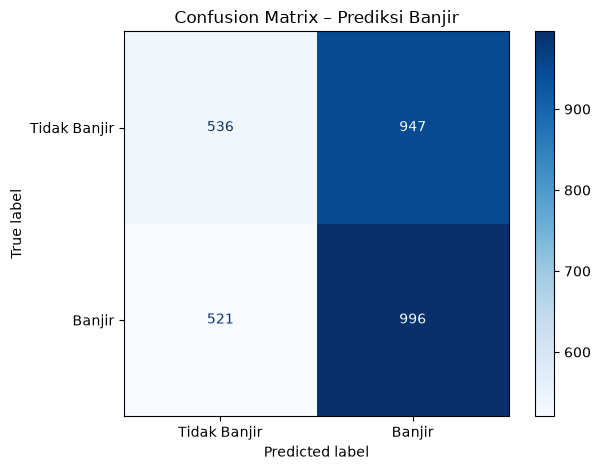

In [4]:
# --- Confusion matrix (4.3), perhitungan manual & scikit-learn (4.4) ---
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')
display(pd.DataFrame(cm, index=['Aktual tidak banjir (0)', 'Aktual banjir (1)'],
                     columns=['Prediksi tidak banjir (0)', 'Prediksi banjir (1)']))

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0

perbandingan = pd.DataFrame({
    'Manual': [accuracy, precision, recall, f1],
    'scikit-learn': [accuracy_score(y_test, y_pred),
                     precision_score(y_test, y_pred, zero_division=0),
                     recall_score(y_test, y_pred, zero_division=0),
                     f1_score(y_test, y_pred, zero_division=0)]
}, index=['Accuracy', 'Precision', 'Recall', 'F1-score']).round(4)
perbandingan['Sama?'] = np.isclose(perbandingan['Manual'], perbandingan['scikit-learn'])
display(perbandingan)

# --- Visualisasi (4.5) ---
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Tidak Banjir', 'Banjir']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Prediksi Banjir')
plt.tight_layout()
plt.show()

**Analisis Tugas 2**

- **Dataset awal:** 10.000 kejadian dengan 13 fitur dan 1 label. Tidak ada nilai kosong. Kelas hampir seimbang (5.057 banjir = 50,57%; 4.943 tidak banjir). Setelah one-hot encoding terdapat 21 fitur.
- **Confusion matrix aktual:** TP=996, TN=536, FP=947, FN=521 pada 3.000 data uji (1.517 banjir, 1.483 tidak banjir).
- **Kesesuaian:** keempat metrik hasil perhitungan manual sama dengan hasil scikit-learn (kolom `Sama?` semuanya `True`). Artinya rumus dan pembacaan sel confusion matrix sudah benar.
- **Hasil:** accuracy 0,511; precision 0,513; recall 0,657; F1 0,576.
- **Interpretasi:** accuracy 51,1% hampir setara tebakan acak. Model banyak memberi alarm banjir (FP=947) dan tetap melewatkan 521 banjir (FN=521). Penjelasan kemungkinan penyebabnya ada pada Tugas 4 dan Bagian 4.9 notebook langkah pengerjaan.

## Tugas 3 — Evaluasi Data Tidak Seimbang
Bandingkan baseline semua tidak banjir dan Decision Tree. Jelaskan mengapa accuracy tinggi belum tentu menunjukkan kemampuan mendeteksi banjir.

,Model,Accuracy,Precision banjir,Recall banjir,F1 banjir
0,Baseline (semua tidak banjir),0.494,0.000,0.000,0.000
1,Decision Tree,0.511,0.513,0.657,0.576


Banjir pada data uji: 1517 dari 3000
Banjir terdeteksi baseline: 0
Banjir terdeteksi Decision Tree: 996

Baseline (semua tidak banjir):
              precision    recall  f1-score   support

           0       0.49      1.00      0.66      1483
           1       0.00      0.00      0.00      1517

    accuracy                           0.49      3000
   macro avg       0.25      0.50      0.33      3000
weighted avg       0.24      0.49      0.33      3000

Decision Tree:
              precision    recall  f1-score   support

           0       0.51      0.36      0.42      1483
           1       0.51      0.66      0.58      1517

    accuracy                           0.51      3000
   macro avg       0.51      0.51      0.50      3000
weighted avg       0.51      0.51      0.50      3000



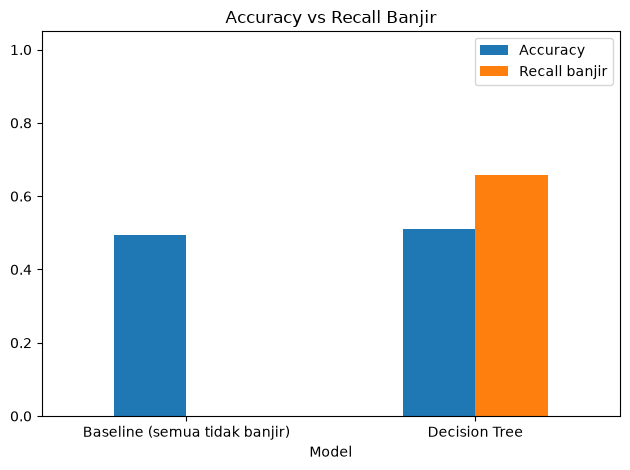

In [5]:
from sklearn.metrics import classification_report

baseline = np.zeros(len(y_test), dtype=int)

def ringkas(nama, pred):
    return {'Model': nama,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision banjir': precision_score(y_test, pred, zero_division=0),
            'Recall banjir': recall_score(y_test, pred, zero_division=0),
            'F1 banjir': f1_score(y_test, pred, zero_division=0)}

tabel_imbalance = pd.DataFrame([ringkas('Baseline (semua tidak banjir)', baseline),
                                ringkas('Decision Tree', y_pred)]).round(3)
display(tabel_imbalance)

print('Banjir pada data uji:', int((y_test == 1).sum()), 'dari', len(y_test))
print('Banjir terdeteksi baseline:', int(((y_test == 1) & (baseline == 1)).sum()))
print('Banjir terdeteksi Decision Tree:', int(((y_test == 1) & (y_pred == 1)).sum()))

print('\nBaseline (semua tidak banjir):')
print(classification_report(y_test, baseline, labels=[0, 1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

tabel_imbalance.set_index('Model')[['Accuracy', 'Recall banjir']].plot(kind='bar', rot=0)
plt.title('Accuracy vs Recall Banjir')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

**Analisis Tugas 3 (bagian 1: data uji asli)**

| Model | Accuracy | Precision banjir | Recall banjir | F1 banjir |
|---|---|---|---|---|
| Baseline (semua tidak banjir) | **0,494** | 0,000 | **0,000** | 0,000 |
| Decision Tree | 0,511 | 0,513 | **0,657** | 0,576 |

- Pada dataset ini kelas **hampir seimbang** (50,6% banjir), sehingga baseline hanya mencapai accuracy 0,494 dan tidak tampak "tinggi". Berbeda dengan studi kasus fraud, accuracy di sini tidak menyesatkan secara mencolok.
- Meski begitu, baseline tidak mendeteksi satu pun banjir (**recall banjir = 0**, 0 dari 1.517), sedangkan Decision Tree mendeteksi 996 dari 1.517 (recall 0,657). Accuracy sendiri tidak menunjukkan perbedaan fungsional ini.
- Selisih accuracy Decision Tree terhadap baseline hanya 1,7 poin persentase, dan precision 0,513 hampir sama dengan proporsi banjir (0,506). Jadi kemampuan membedakan kelas hampir tidak ada.

In [6]:
# Ilustrasi: bagaimana jika banjir sangat jarang (3% dari data uji)?
idx_neg = y_test[y_test == 0].index
idx_pos = y_test[y_test == 1].sample(n=46, random_state=42).index
idx = idx_neg.union(idx_pos)
X_s, y_s = X_test.loc[idx], y_test.loc[idx]
pred_s = model.predict(X_s)
base_s = np.zeros(len(y_s), dtype=int)

print('Data uji ilustrasi:', len(y_s), '| Proporsi banjir:', round(y_s.mean(), 3))
display(pd.DataFrame([
    {'Model': 'Baseline (semua tidak banjir)', 'Accuracy': accuracy_score(y_s, base_s),
     'Precision': precision_score(y_s, base_s, zero_division=0),
     'Recall': recall_score(y_s, base_s, zero_division=0)},
    {'Model': 'Decision Tree', 'Accuracy': accuracy_score(y_s, pred_s),
     'Precision': precision_score(y_s, pred_s, zero_division=0),
     'Recall': recall_score(y_s, pred_s, zero_division=0)}]).round(3))

Data uji ilustrasi: 1529 | Proporsi banjir: 0.03


,Model,Accuracy,Precision,Recall
0,Baseline (semua tidak banjir),0.970,0.000,0.000
1,Decision Tree,0.373,0.036,0.761


**Analisis Tugas 3 (bagian 2: ilustrasi data tidak seimbang)**

Untuk memperlihatkan inti pertanyaan Tugas 3, data uji disimulasikan menjadi tidak seimbang: semua 1.483 kejadian tidak banjir dipertahankan dan hanya 46 banjir diambil secara acak (banjir ≈ 3%).

| Model | Accuracy | Precision | Recall |
|---|---|---|---|
| Baseline (semua tidak banjir) | **0,970** | 0,000 | **0,000** |
| Decision Tree | 0,373 | 0,036 | 0,761 |

- Begitu banjir menjadi jarang, baseline langsung mencapai **accuracy 97%** padahal tidak mendeteksi satu pun banjir, sedangkan Decision Tree yang benar-benar mencoba mendeteksi justru accuracy-nya turun menjadi 37,3%.
- **Mengapa accuracy menyesatkan:** accuracy menghitung semua prediksi benar secara sama rata, sehingga didominasi kelas mayoritas. Model yang hanya menebak kelas mayoritas terlihat bagus, padahal kemampuan pada kelas minoritas yang penting (banjir) nol.
- **Metrik yang sesuai:** recall, precision, dan F1 pada kelas banjir (serta PR-AUC atau macro-F1), disertai pembacaan confusion matrix.
- Catatan: ilustrasi ini hasil simulasi pada data uji, bukan data nyata yang tidak seimbang. Angka pada Decision Tree dipengaruhi oleh pengambilan sampel 46 banjir.

## Tugas 4 — Eksperimen dan Rekomendasi
Uji empat threshold. Buat tabel precision dan recall, pilih threshold untuk skenario biaya FN lebih tinggi daripada FP, dan berikan argumentasi berbasis hasil.

Nilai probabilitas unik pada data uji: [0.231 0.349 0.438 0.468 0.505 0.54  0.658 0.678 0.847 1.   ]
ROC-AUC data uji: 0.509


,Threshold,Precision,Recall,TP,FP,FN,TN
0,0.2,0.506,1.000,1517,1483,0,0
1,0.4,0.506,0.989,1500,1465,17,18
2,0.5,0.513,0.657,996,947,521,536
3,0.7,0.500,0.003,5,5,1512,1478


Threshold terpilih untuk skenario FN lebih mahal: 0.2
Recall = 1.0 | Precision = 0.506 | FN = 0 | FP = 1483


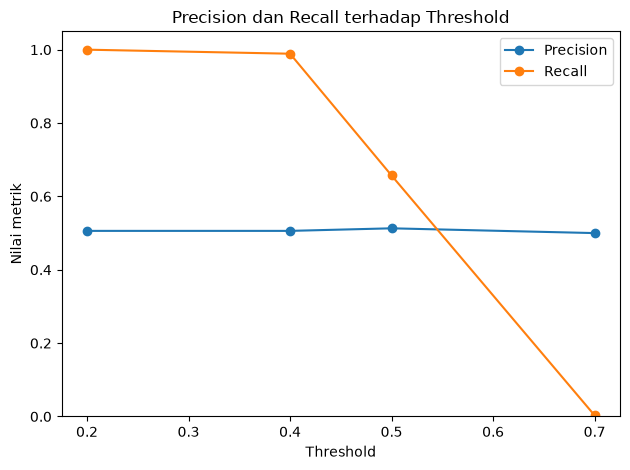

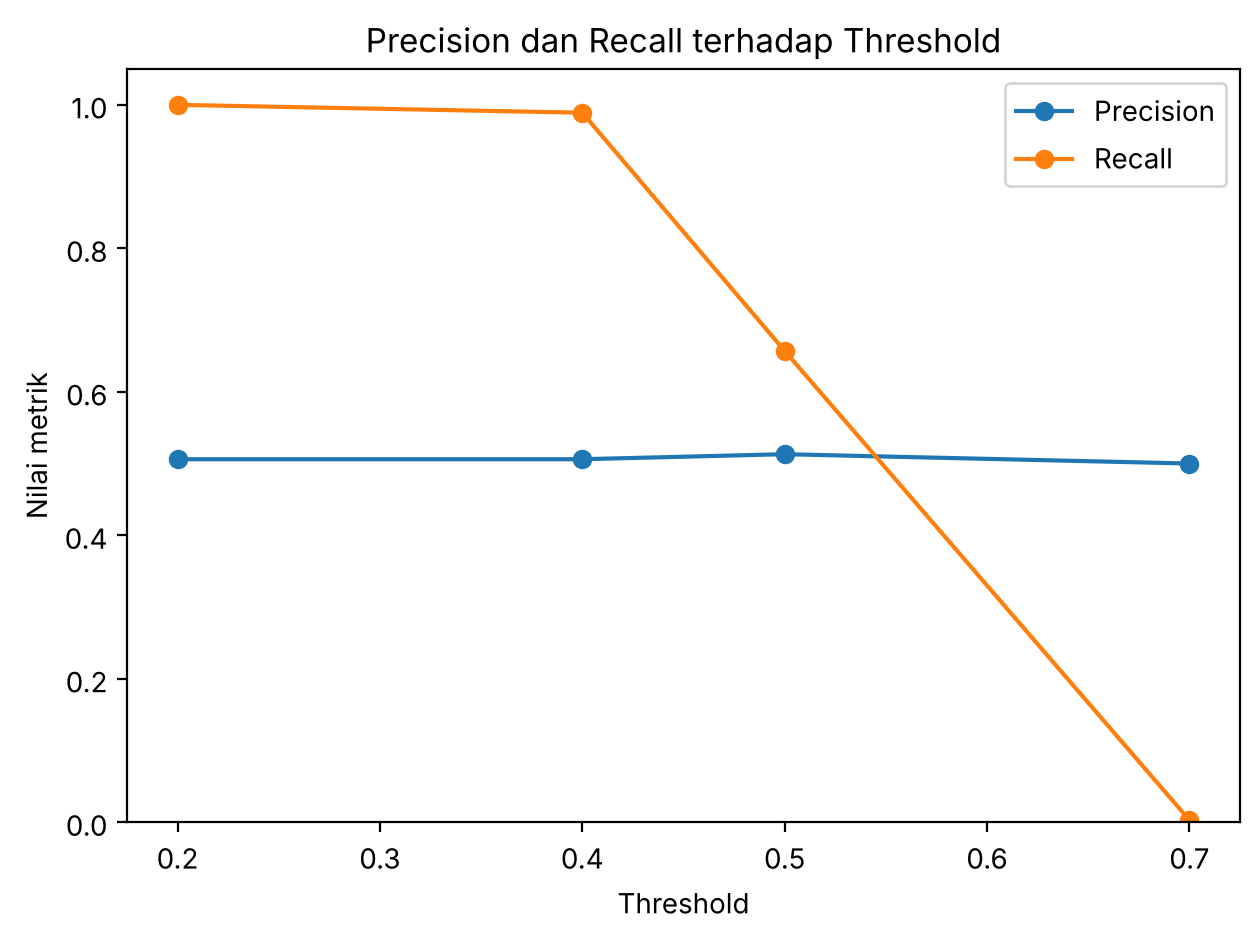

In [7]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
print('Nilai probabilitas unik pada data uji:', np.unique(y_prob).round(3))
print('ROC-AUC data uji:', round(roc_auc_score(y_test, y_prob), 3))

baris = []
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    baris.append({'Threshold': threshold,
                  'Precision': round(precision_score(y_test, pred, zero_division=0), 3),
                  'Recall': round(recall_score(y_test, pred, zero_division=0), 3),
                  'TP': tp_, 'FP': fp_, 'FN': fn_, 'TN': tn_})
tabel_threshold = pd.DataFrame(baris)
display(tabel_threshold)

# Skenario biaya FN > FP: utamakan recall, lalu precision, lalu threshold terendah
pilihan = tabel_threshold.sort_values(['Recall', 'Precision', 'Threshold'],
                                      ascending=[False, False, True]).iloc[0]
print('Threshold terpilih untuk skenario FN lebih mahal:', pilihan['Threshold'])
print('Recall =', pilihan['Recall'], '| Precision =', pilihan['Precision'],
      '| FN =', int(pilihan['FN']), '| FP =', int(pilihan['FP']))

plt.plot(tabel_threshold['Threshold'], tabel_threshold['Precision'], marker='o', label='Precision')
plt.plot(tabel_threshold['Threshold'], tabel_threshold['Recall'], marker='o', label='Recall')
plt.xlabel('Threshold'); plt.ylabel('Nilai metrik'); plt.ylim(0, 1.05)
plt.title('Precision dan Recall terhadap Threshold')
plt.legend(); plt.tight_layout(); plt.show()

**Analisis Tugas 4**

| Threshold | Precision | Recall | TP | FP | FN | TN |
|---|---|---|---|---|---|---|
| 0,2 | 0,506 | 1,000 | 1.517 | 1.483 | 0 | 0 |
| 0,4 | 0,506 | 0,989 | 1.500 | 1.465 | 17 | 18 |
| 0,5 | 0,513 | 0,657 | 996 | 947 | 521 | 536 |
| 0,7 | 0,500 | 0,003 | 5 | 5 | 1.512 | 1.478 |

- Menurunkan threshold **menaikkan recall** (0,657 → 0,989 → 1,000), sedangkan menaikkannya ke 0,7 menjatuhkan recall menjadi 0,003 (FN = 1.512).
- **Precision hampir tetap** (0,500–0,513), selalu mendekati proporsi banjir (0,506). Jadi tidak ada threshold yang membuat alarm lebih akurat.
- Probabilitas terendah dari pohon adalah 0,231, sehingga pada threshold 0,2 seluruh data diprediksi banjir (FN = 0 tetapi TN = 0 dan FP = 1.483).
- **Rekomendasi untuk skenario biaya FN lebih tinggi daripada FP:** secara kriteria, pilih threshold **rendah**. Threshold 0,2 memberikan recall maksimum (1,000; FN = 0), dan threshold 0,4 hampir sama (recall 0,989; FN = 17) dengan 18 kejadian tidak banjir yang dikenali benar. Threshold 0,7 tidak layak karena hampir semua banjir terlewat.
- **Peringatan penting:** recall tinggi pada threshold rendah di sini diperoleh dengan **menandai hampir semua kejadian sebagai banjir**. ROC-AUC data uji hanya **0,509** (0,5 = tebakan acak), sehingga model tidak benar-benar membedakan banjir dari bukan banjir. Rekomendasi threshold hanya valid secara metodologis untuk praktikum. Untuk penggunaan nyata, perlu fitur yang lebih informatif atau data yang lebih baik, bukan sekadar mengubah threshold.